## Attribute Information

Below there are the description of the attributes that will be used in our model for better understanding of the data:

- `LIMIT_BAL`: Amount of the given credit (NT dollar). It includes both the individual consumer credit and his/her family (supplementary) credit.
- `SEX`: Gender (1 = male; 2 = female).
- `EDUCATION`: Education (1 = graduate school; 2 = university; 3 = high school; 4 = others).
- `MARRIAGE`: Marital status (1 = married; 2 = single; 3 = others).
- `AGE`: Age (year).
- `PAY_1`: the repayment status in September, 2005.
- `PAY_2`: the repayment status in August, 2005.
- `PAY_3`: the repayment status in July, 2005.
- `PAY_4`: the repayment status in June, 2005.
- `PAY_5`: the repayment status in May, 2005.
- `PAY_6`: the repayment status in April, 2005.
- `BILL_AMT1`: Amount of bill statement (NT dollar). Amount of bill statement in September, 2005.
- `BILL_AMT2`: Amount of bill statement (NT dollar). Amount of bill statement in August, 2005.
- `BILL_AMT3`: Amount of bill statement (NT dollar). Amount of bill statement in July, 2005.
- `BILL_AMT4`: Amount of bill statement (NT dollar). Amount of bill statement in June, 2005.
- `BILL_AMT5`: Amount of bill statement (NT dollar). Amount of bill statement in May, 2005.
- `BILL_AMT6`: Amount of bill statement (NT dollar). Amount of bill statement in April, 2005.
- `PAY_AMT1`: Amount of previous payment (NT dollar). Amount paid in September, 2005.
- `PAY_AMT2`: Amount of previous payment (NT dollar). Amount paid in August, 2005.
- `PAY_AMT3`: Amount of previous payment (NT dollar). Amount paid in July, 2005.
- `PAY_AMT4`: Amount of previous payment (NT dollar). Amount paid in June, 2005.
- `PAY_AMT5`: Amount of previous payment (NT dollar). Amount paid in May, 2005.
- `PAY_AMT6`: Amount of previous payment (NT dollar). Amount paid in June, 2005.
- `dpnm`: Default payment next month.(Yes = 1, No = 0)

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("UCI_Credit_Card.csv")
df = df.rename(columns={'default.payment.next.month': 'def_pay', 
                        'PAY_0': 'PAY_1'})

In [3]:
# Drop "ID" column.
data=df.drop(['ID'], axis=1)
print(f"There are {data.duplicated().sum()} duplicate rows in the data set.")
# Duplicate rows are removed.
df = df[~data.duplicated()]

There are 35 duplicate rows in the data set.


In [4]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,def_pay
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 29965 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         29965 non-null  int64  
 1   LIMIT_BAL  29965 non-null  float64
 2   SEX        29965 non-null  int64  
 3   EDUCATION  29965 non-null  int64  
 4   MARRIAGE   29965 non-null  int64  
 5   AGE        29965 non-null  int64  
 6   PAY_1      29965 non-null  int64  
 7   PAY_2      29965 non-null  int64  
 8   PAY_3      29965 non-null  int64  
 9   PAY_4      29965 non-null  int64  
 10  PAY_5      29965 non-null  int64  
 11  PAY_6      29965 non-null  int64  
 12  BILL_AMT1  29965 non-null  float64
 13  BILL_AMT2  29965 non-null  float64
 14  BILL_AMT3  29965 non-null  float64
 15  BILL_AMT4  29965 non-null  float64
 16  BILL_AMT5  29965 non-null  float64
 17  BILL_AMT6  29965 non-null  float64
 18  PAY_AMT1   29965 non-null  float64
 19  PAY_AMT2   29965 non-null  float64
 20  PAY_AMT3   

In [6]:
# Gender (1 = male; 2 = female).
df.SEX.value_counts()

SEX
2    18091
1    11874
Name: count, dtype: int64

array([[<Axes: title={'center': 'SEX'}>]], dtype=object)

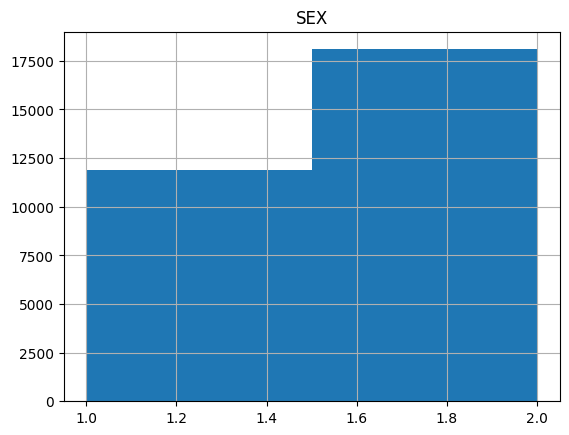

In [7]:
df.hist(column='SEX', bins=2)

In [8]:
#  Marital status (1 = married; 2 = single; 3 = others).
df.MARRIAGE.value_counts()

MARRIAGE
2    15945
1    13643
3      323
0       54
Name: count, dtype: int64

In [9]:
df.loc[df.MARRIAGE == 0, 'MARRIAGE'] = 3
df.MARRIAGE.value_counts()

MARRIAGE
2    15945
1    13643
3      377
Name: count, dtype: int64

array([[<Axes: title={'center': 'MARRIAGE'}>]], dtype=object)

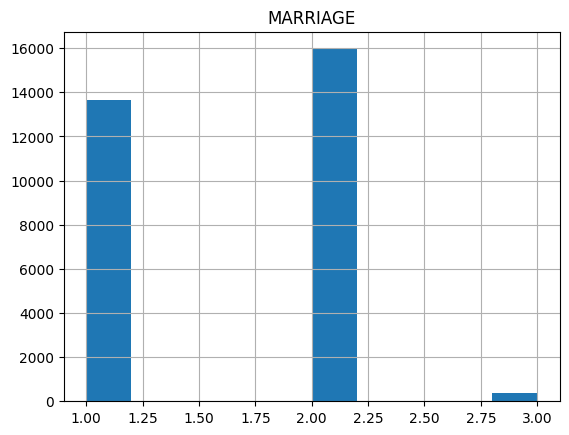

In [10]:
df.hist(column='MARRIAGE')

In [11]:
# Education (1 = graduate school; 2 = university; 3 = high school; 4 = others).
df.EDUCATION.value_counts() 

EDUCATION
2    14019
1    10563
3     4915
5      280
4      123
6       51
0       14
Name: count, dtype: int64

In [12]:
fil = (df.EDUCATION == 5) | (df.EDUCATION == 6) | (df.EDUCATION == 0)
df.loc[fil, 'EDUCATION'] = 4
df.EDUCATION.value_counts()

EDUCATION
2    14019
1    10563
3     4915
4      468
Name: count, dtype: int64

array([[<Axes: title={'center': 'EDUCATION'}>]], dtype=object)

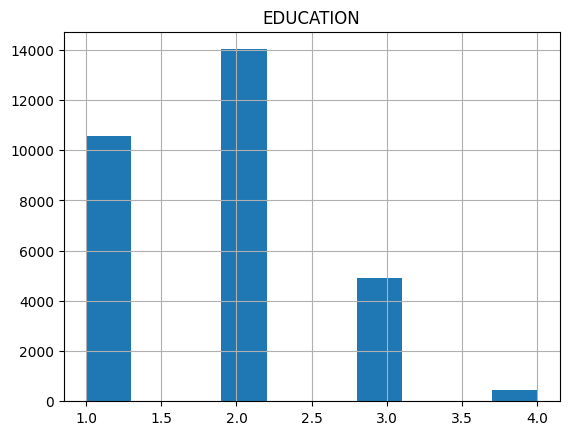

In [13]:
df.hist(column='EDUCATION')

In [14]:
df.LIMIT_BAL.describe(), 

(count      29965.000000
 mean      167442.005006
 std       129760.135222
 min        10000.000000
 25%        50000.000000
 50%       140000.000000
 75%       240000.000000
 max      1000000.000000
 Name: LIMIT_BAL, dtype: float64,)

array([[<Axes: title={'center': 'LIMIT_BAL'}>]], dtype=object)

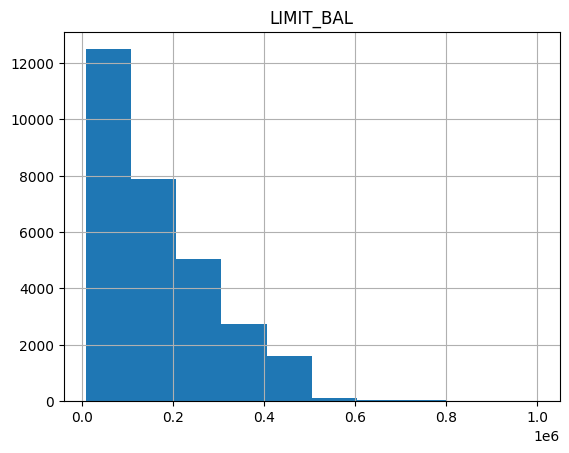

In [15]:
df.hist(column='LIMIT_BAL')

In [16]:
df.AGE.describe()

count    29965.000000
mean        35.487969
std          9.219459
min         21.000000
25%         28.000000
50%         34.000000
75%         41.000000
max         79.000000
Name: AGE, dtype: float64

array([[<Axes: title={'center': 'AGE'}>]], dtype=object)

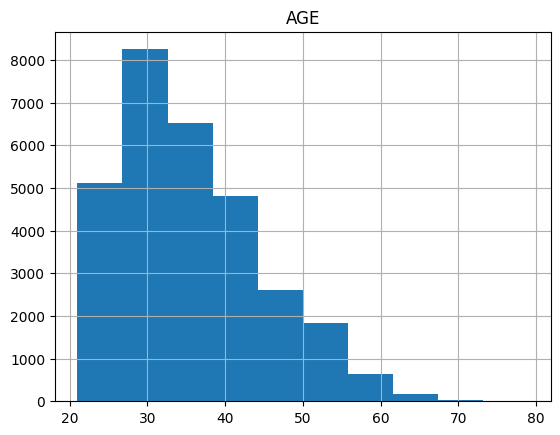

In [17]:
df.hist(column='AGE')

In [18]:
df.PAY_1.describe()

count    29965.000000
mean        -0.016753
std          1.123492
min         -2.000000
25%         -1.000000
50%          0.000000
75%          0.000000
max          8.000000
Name: PAY_1, dtype: float64

array([[<Axes: title={'center': 'PAY_1'}>]], dtype=object)

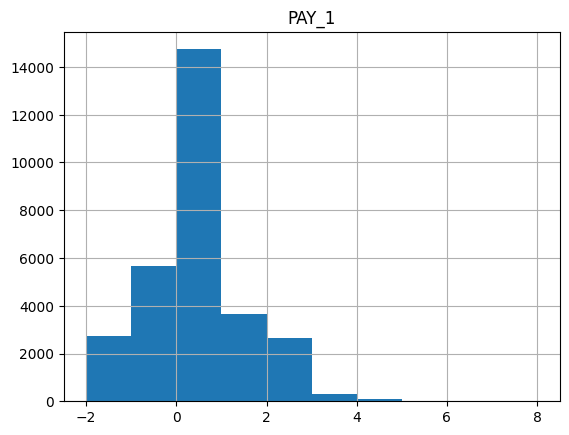

In [19]:
df.hist(column='PAY_1')

In [20]:
df.BILL_AMT1.describe()

count     29965.000000
mean      51283.009778
std       73658.132403
min     -165580.000000
25%        3595.000000
50%       22438.000000
75%       67260.000000
max      964511.000000
Name: BILL_AMT1, dtype: float64

array([[<Axes: title={'center': 'BILL_AMT1'}>]], dtype=object)

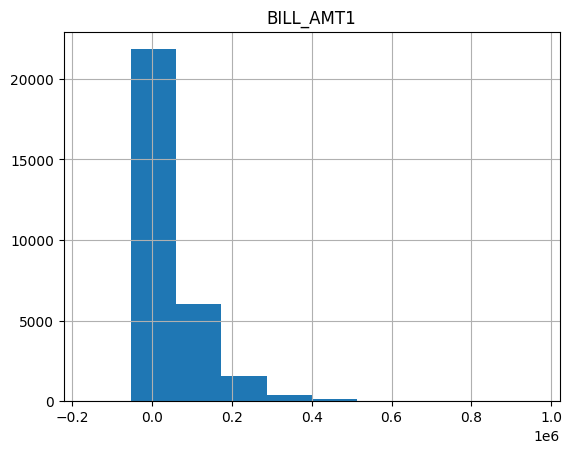

In [21]:
df.hist(column='BILL_AMT1')

In [22]:
df.PAY_AMT1.describe()

count     29965.000000
mean       5670.099316
std       16571.849467
min           0.000000
25%        1000.000000
50%        2102.000000
75%        5008.000000
max      873552.000000
Name: PAY_AMT1, dtype: float64

array([[<Axes: title={'center': 'PAY_AMT1'}>]], dtype=object)

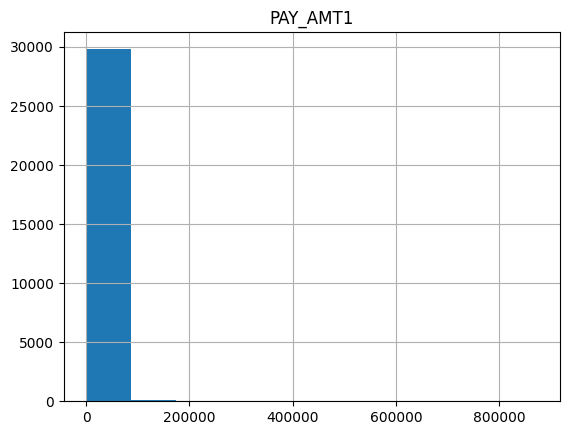

In [23]:
df.hist(column='PAY_AMT1')

In [24]:
df[['PAY_AMT3','BILL_AMT4','PAY_4']]

,PAY_AMT3,BILL_AMT4,PAY_4
0,0.0,0.0,-1
1,1000.0,3272.0,0
2,1000.0,14331.0,0
3,1200.0,28314.0,0
4,10000.0,20940.0,0
...,...,...,...
29995,5003.0,88004.0,0
29996,8998.0,8979.0,-1
29997,22000.0,20878.0,-1
29998,1178.0,52774.0,0


In [25]:
tempd_df = df[df.ID == 107].T

In [26]:
# The repayment status
tempd_df[6:12]

,106
PAY_1,-1.0
PAY_2,-1.0
PAY_3,-1.0
PAY_4,-1.0
PAY_5,-1.0
PAY_6,-1.0


In [27]:
# Amount of bill statement
tempd_df[12:18]

,106
BILL_AMT1,6108.0
BILL_AMT2,2861.0
BILL_AMT3,3277.0
BILL_AMT4,3319.0
BILL_AMT5,1150.0
BILL_AMT6,1150.0


In [28]:
# Amount of previous payment
tempd_df[18:24]

,106
PAY_AMT1,2861.0
PAY_AMT2,3279.0
PAY_AMT3,3319.0
PAY_AMT4,1150.0
PAY_AMT5,1150.0
PAY_AMT6,1035.0


In [29]:
tempd_df2 = df[df.ID == 163].T

In [30]:
# The repayment status
tempd_df2[6:12]

,162
PAY_1,-1.0
PAY_2,-1.0
PAY_3,-1.0
PAY_4,-1.0
PAY_5,0.0
PAY_6,-1.0


In [31]:
# Amount of bill statement
tempd_df2[12:18]

,162
BILL_AMT1,1234.0
BILL_AMT2,396.0
BILL_AMT3,396.0
BILL_AMT4,792.0
BILL_AMT5,396.0
BILL_AMT6,423.0


In [32]:
# Amount of previous payment
tempd_df2[18:24]

,162
PAY_AMT1,396.0
PAY_AMT2,396.0
PAY_AMT3,792.0
PAY_AMT4,0.0
PAY_AMT5,423.0
PAY_AMT6,369.0


In [48]:
new_df = df.drop(columns=['BILL_AMT1', 'PAY_AMT6','def_pay','PAY_1','PAY_2'])
new_df

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5
0,1,20000.0,2,2,1,24,-1,-1,-2,-2,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0
1,2,120000.0,2,2,2,26,0,0,0,2,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0
2,3,90000.0,2,2,2,34,0,0,0,0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0
3,4,50000.0,2,2,1,37,0,0,0,0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0
4,5,50000.0,1,2,1,57,-1,0,0,0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000.0,1,3,1,39,0,0,0,0,192815.0,208365.0,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0
29996,29997,150000.0,1,3,2,43,-1,-1,0,0,1828.0,3502.0,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0
29997,29998,30000.0,1,2,2,37,2,-1,0,0,3356.0,2758.0,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0
29998,29999,80000.0,1,3,1,41,0,0,0,-1,78379.0,76304.0,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0


In [49]:
def compute_transform(x, y):
    if ((x == 0) and (y == 0)):
        return 100
    elif y < 0:
        return 0
    elif y == 0:
        return 0
    else:
        return (x / y ) * 100

new_df['September_Percent'] = new_df.apply(lambda x : compute_transform(x['PAY_AMT1'], x['BILL_AMT2']) , axis=1)
new_df['August_Percent'] = new_df.apply(lambda x : compute_transform(x['PAY_AMT2'], x['BILL_AMT3']) , axis=1)
new_df['July_Percent'] = new_df.apply(lambda x : compute_transform(x['PAY_AMT3'], x['BILL_AMT4']) , axis=1)
new_df['June_Percent'] = new_df.apply(lambda x : compute_transform(x['PAY_AMT4'], x['BILL_AMT5']) , axis=1)
new_df['May_Percent'] = new_df.apply(lambda x : compute_transform(x['PAY_AMT5'], x['BILL_AMT6']) , axis=1)

In [50]:
new_df = new_df.rename(columns={'PAY_3': 'August_Status', 
                        'PAY_4': 'July_Status',
                        'PAY_5': 'June_Status',
                        'PAY_6': 'May_Status'})

In [51]:
new_df = new_df.drop(columns=['PAY_AMT1', 'PAY_AMT2','PAY_AMT3','PAY_AMT4','PAY_AMT5','BILL_AMT2','BILL_AMT3','BILL_AMT4','BILL_AMT5','BILL_AMT6'])

In [52]:
new_df[['September_Percent', 'August_Percent', 'July_Percent', 'June_Percent','May_Percent']].describe()

,September_Percent,August_Percent,July_Percent,June_Percent,May_Percent
count,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000
mean,55.560779,74.353284,55.860611,41.490602,48.704836
std,2569.482934,3870.383157,2569.864228,119.540998,507.845532
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.300161,4.280599,3.669126,3.600646,3.723260
50%,8.965501,9.061979,7.509924,6.756985,7.682610
75%,100.000000,100.000000,100.000000,100.000000,100.000000
max,444433.333333,500100.000000,444433.333333,12970.512821,69065.517241


In [53]:
new_df

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,August_Status,July_Status,June_Status,May_Status,September_Percent,August_Percent,July_Percent,June_Percent,May_Percent
0,1,20000.0,2,2,1,24,-1,-1,-2,-2,0.000000,100.000000,100.000000,100.000000,100.000000
1,2,120000.0,2,2,2,26,0,0,0,2,0.000000,37.285608,30.562347,28.943560,0.000000
2,3,90000.0,2,2,2,34,0,0,0,0,10.821986,11.062763,6.977880,6.689858,6.431282
3,4,50000.0,2,2,1,37,0,0,0,0,4.146539,4.096082,4.238186,3.798474,3.617965
4,5,50000.0,1,2,1,57,-1,0,0,0,35.273369,102.360820,47.755492,47.007208,3.601485
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000.0,1,3,1,39,0,0,0,0,4.408371,9.598541,5.684969,9.754458,31.289111
29996,29997,150000.0,1,3,2,43,-1,-1,0,0,100.492341,100.685323,100.211605,2.485549,100.000000
29997,29998,30000.0,1,2,2,37,2,-1,0,0,0.000000,0.000000,105.374078,20.406180,10.332180
29998,29999,80000.0,1,3,1,41,0,0,0,-1,109.595683,4.467656,2.232160,16.246310,108.213468


In [54]:
new_df[new_df.ID == 163].T

,162
ID,163.0
LIMIT_BAL,290000.0
SEX,1.0
EDUCATION,3.0
MARRIAGE,1.0
AGE,47.0
August_Status,-1.0
July_Status,-1.0
June_Status,0.0
May_Status,-1.0


In [55]:
new_df[new_df.ID == 107].T

,106
ID,107.000000
LIMIT_BAL,80000.000000
SEX,2.000000
EDUCATION,2.000000
MARRIAGE,1.000000
AGE,36.000000
August_Status,-1.000000
July_Status,-1.000000
June_Status,-1.000000
May_Status,-1.000000


In [56]:
df[df.ID == 6555].T

,6554
ID,6555.0
LIMIT_BAL,180000.0
SEX,1.0
EDUCATION,1.0
MARRIAGE,2.0
AGE,28.0
PAY_1,-2.0
PAY_2,-2.0
PAY_3,-2.0
PAY_4,-2.0


In [57]:
df[df.ID == 3413].T

,3412
ID,3413.0
LIMIT_BAL,160000.0
SEX,2.0
EDUCATION,2.0
MARRIAGE,2.0
AGE,50.0
PAY_1,-2.0
PAY_2,-2.0
PAY_3,-2.0
PAY_4,-2.0


# Linear Regression Test

In [58]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
import numpy as np

In [59]:
new_df.drop(columns=['ID'], inplace=True)

In [60]:
new_df

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,August_Status,July_Status,June_Status,May_Status,September_Percent,August_Percent,July_Percent,June_Percent,May_Percent
0,20000.0,2,2,1,24,-1,-1,-2,-2,0.000000,100.000000,100.000000,100.000000,100.000000
1,120000.0,2,2,2,26,0,0,0,2,0.000000,37.285608,30.562347,28.943560,0.000000
2,90000.0,2,2,2,34,0,0,0,0,10.821986,11.062763,6.977880,6.689858,6.431282
3,50000.0,2,2,1,37,0,0,0,0,4.146539,4.096082,4.238186,3.798474,3.617965
4,50000.0,1,2,1,57,-1,0,0,0,35.273369,102.360820,47.755492,47.007208,3.601485
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,220000.0,1,3,1,39,0,0,0,0,4.408371,9.598541,5.684969,9.754458,31.289111
29996,150000.0,1,3,2,43,-1,-1,0,0,100.492341,100.685323,100.211605,2.485549,100.000000
29997,30000.0,1,2,2,37,2,-1,0,0,0.000000,0.000000,105.374078,20.406180,10.332180
29998,80000.0,1,3,1,41,0,0,0,-1,109.595683,4.467656,2.232160,16.246310,108.213468


In [62]:
X_train, X_test, y_train, y_test = train_test_split(new_df.drop(columns=['September_Percent']), new_df['September_Percent'], test_size=0.2, random_state=42)

In [65]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((23972, 13), (5993, 13), (23972,), (5993,))

In [70]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [71]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
mean_squared_error(y_test, linear_model.predict(X_test))

np.float64(37862.79731778138)

In [76]:
from sklearn.svm import SVR

svr_model = SVR()
svr_model.fit(X_train, y_train)
mean_squared_error(y_test, svr_model.predict(X_test))

np.float64(2895.4966662904567)

In [77]:
svr_model.predict(X_test)

array([ 7.80349762, 52.77614536, 24.84250803, ...,  8.43693204,
       99.80954913,  4.51775972], shape=(5993,))

In [78]:
y_test

29334     11.435547
24426    100.000000
9822       6.119639
20887      4.992906
21692      4.538097
            ...    
22574      3.637055
9304      15.850090
6556       0.000000
22686    100.367197
15854      4.424443
Name: September_Percent, Length: 5993, dtype: float64